In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the Iris dataset

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = iris.target
df["species_name"] = df["species"].map(
    dict(enumerate(iris.target_names))
)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
# Dataset shape

print("Dataset shape:", df.shape)

# Data types and information

df.info()

Dataset shape: (150, 6)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
 5   species_name       150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [4]:
# Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())

# Descriptive statistics

print("\nDescriptive statistics:")
df.describe()

Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
species_name         0
dtype: int64

Descriptive statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [5]:
# Check the number of samples in each species

species_counts = df["species_name"].value_counts()

print("Number of samples in each species:")
print(species_counts)

Number of samples in each species:
species_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


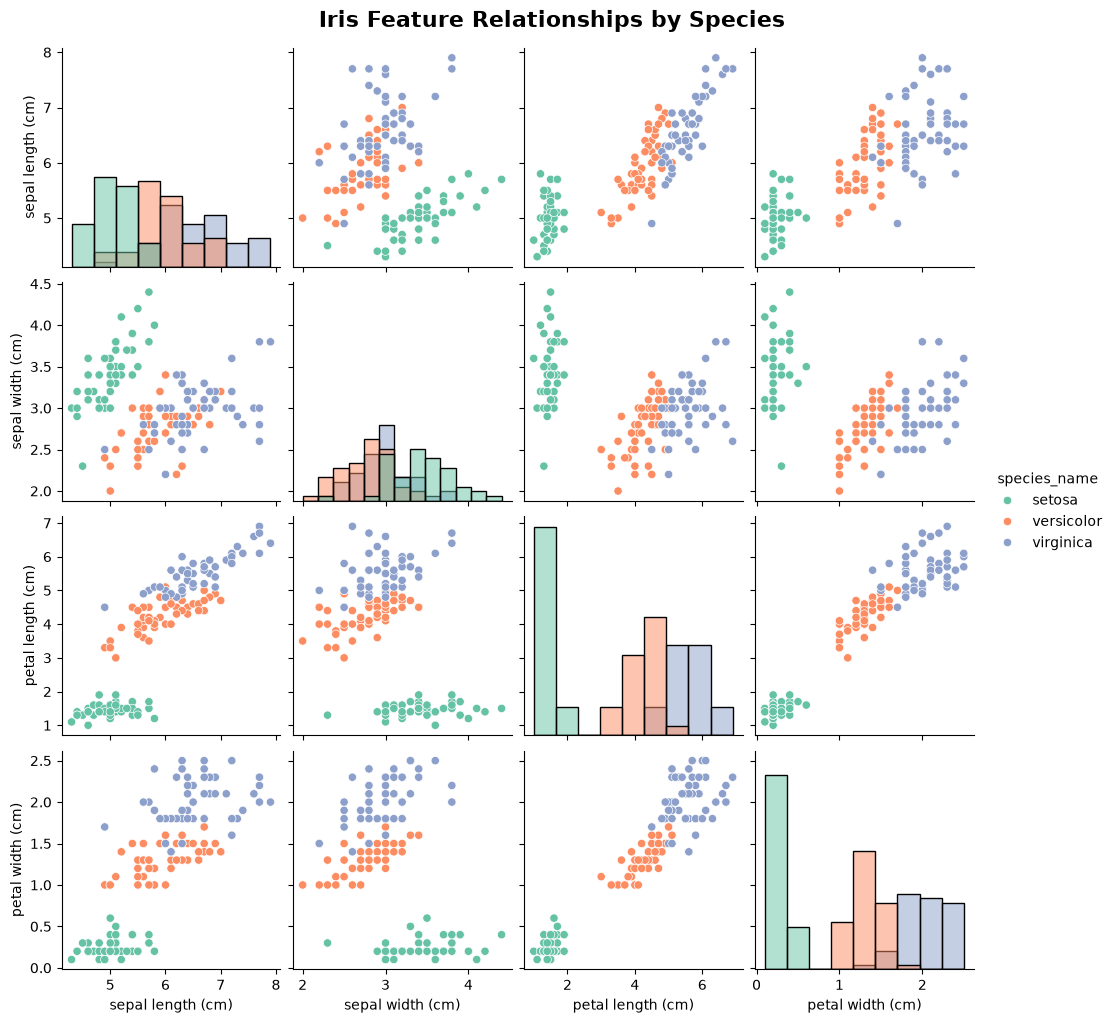

In [6]:
# Pairplot of Iris features by species

sns.pairplot(
    df,
    vars=iris.feature_names,
    hue="species_name",
    palette="Set2",
    diag_kind="hist"
)

plt.suptitle(
    "Iris Feature Relationships by Species",
    y=1.02,
    fontsize=16,
    fontweight="bold"
)

plt.show()

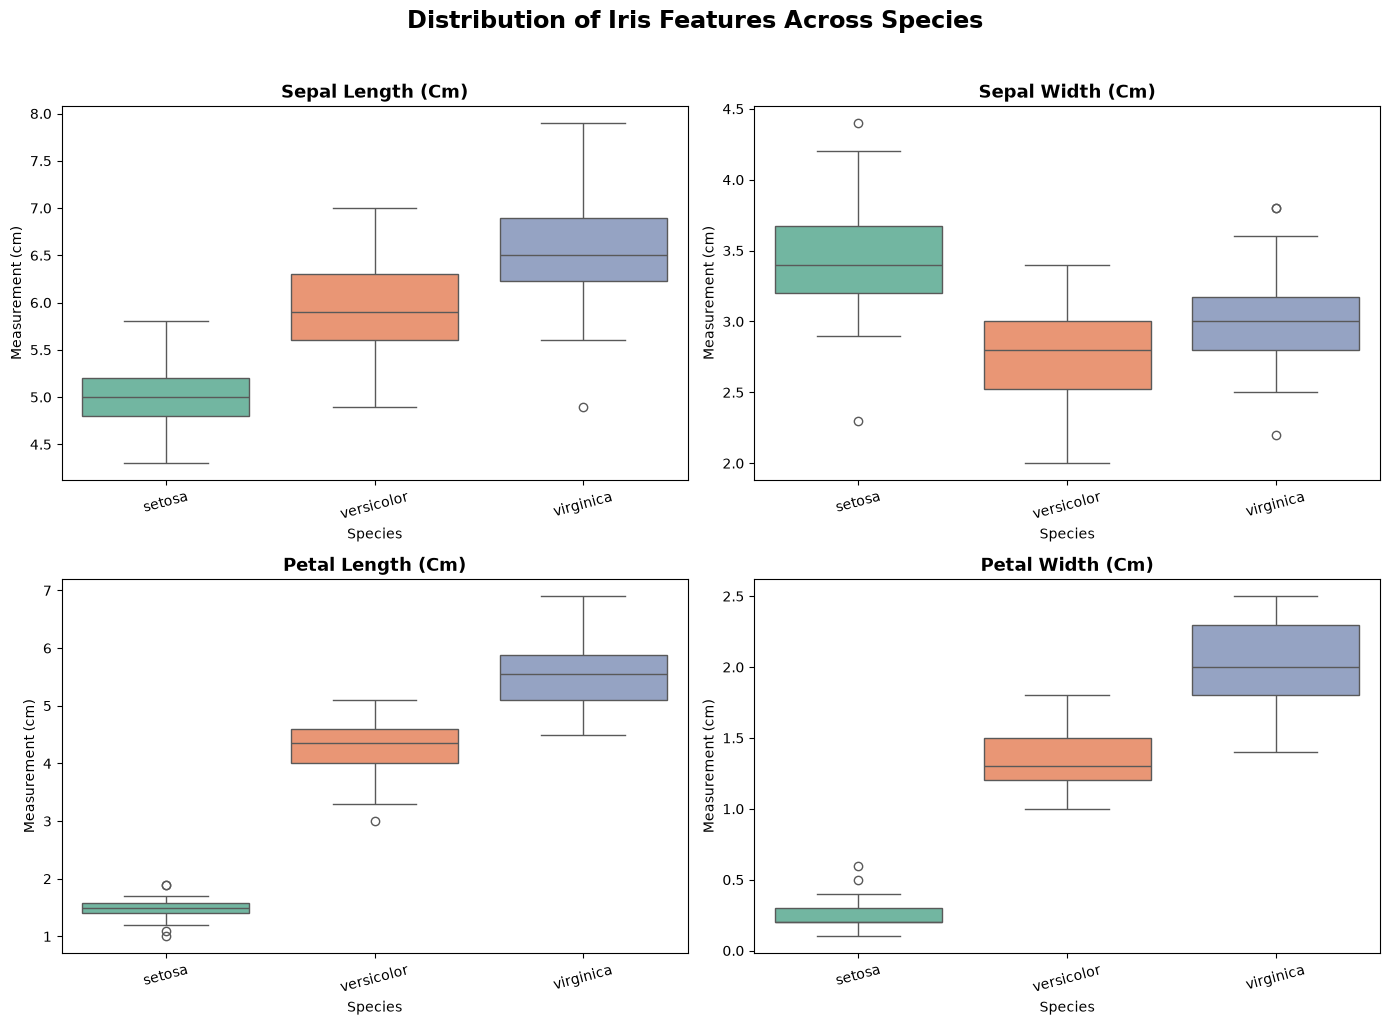

In [7]:
# Box plots for each Iris feature by species

plt.figure(figsize=(14, 10))

for i, feature in enumerate(iris.feature_names, 1):
    plt.subplot(2, 2, i)

    sns.boxplot(
        data=df,
        x="species_name",
        y=feature,
        hue="species_name",
        palette="Set2",
        legend=False
    )

    plt.title(feature.title(), fontsize=13, fontweight="bold")
    plt.xlabel("Species")
    plt.ylabel("Measurement (cm)")
    plt.xticks(rotation=15)

plt.suptitle(
    "Distribution of Iris Features Across Species",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

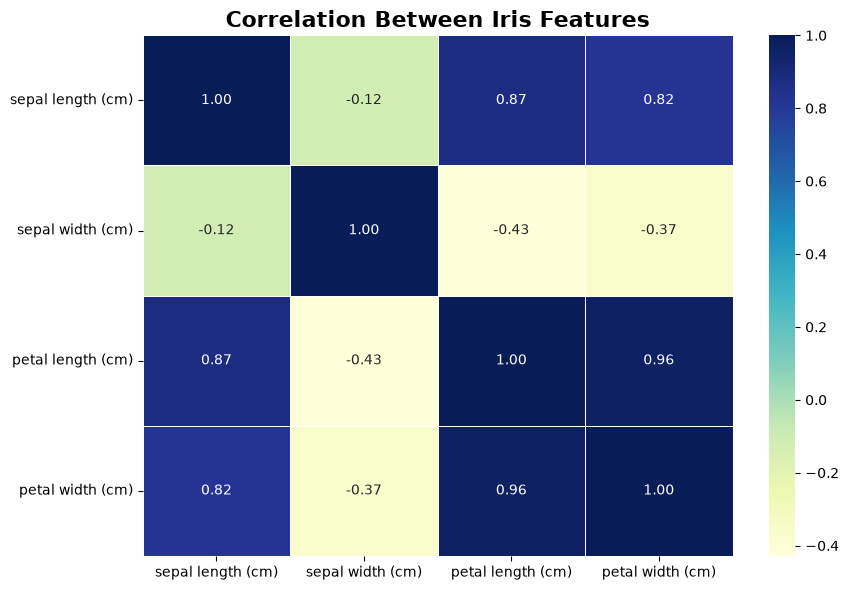

In [8]:
# Correlation heatmap

plt.figure(figsize=(9, 6))

correlation = df[iris.feature_names].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    linewidths=0.5
)

plt.title(
    "Correlation Between Iris Features",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Feature Selection Discussion

The exploratory analysis shows that petal length and petal width are the most discriminative features for distinguishing the three Iris species. The pairplot and box plots show clear separation between species based on these two features, particularly for Setosa. Sepal length and sepal width show comparatively more overlap between Versicolor and Virginica.

Therefore, all four numerical features will be retained for model training because they contain useful information, while petal length and petal width appear to contribute most strongly to species classification.

In [9]:
# Select features and target

X = df[iris.feature_names]
y = df["species"]

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

Features (X):
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target (y):
0    0
1    0
2    0
3    0
4    0
Name: species, dtype: int64


In [10]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (120, 4)
Testing set size: (30, 4)


In [11]:
# Train Logistic Regression model

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=200))
])

logistic_model.fit(X_train, y_train)

# Make predictions
y_pred_logistic = logistic_model.predict(X_test)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [12]:
# Evaluate Logistic Regression

logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:", logistic_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=iris.target_names
    )
)

Logistic Regression Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [13]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("KNN predictions:", y_pred_knn)

KNN predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


In [14]:
# Evaluate KNN

knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", knn_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=iris.target_names
    )
)

KNN Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [15]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("Decision Tree predictions:", y_pred_dt)

Decision Tree predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [16]:
# Evaluate Decision Tree

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=iris.target_names
    )
)

Decision Tree Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [17]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest predictions:", y_pred_rf)

Random Forest predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 2 1 0 2 0]


In [18]:
# Evaluate Random Forest

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=iris.target_names
    )
)

Random Forest Accuracy: 0.9

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [19]:
# Compare model accuracies

model_accuracies = {
    "Logistic Regression": logistic_accuracy,
    "KNN": knn_accuracy,
    "Decision Tree": dt_accuracy,
    "Random Forest": rf_accuracy
}

for model, accuracy in model_accuracies.items():
    print(f"{model}: {accuracy:.2%}")

Logistic Regression: 93.33%
KNN: 100.00%
Decision Tree: 93.33%
Random Forest: 90.00%


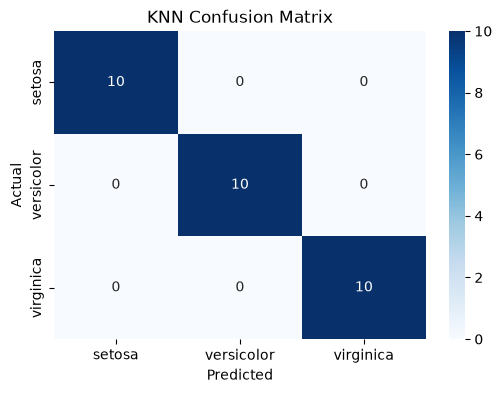

In [20]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")
plt.show()

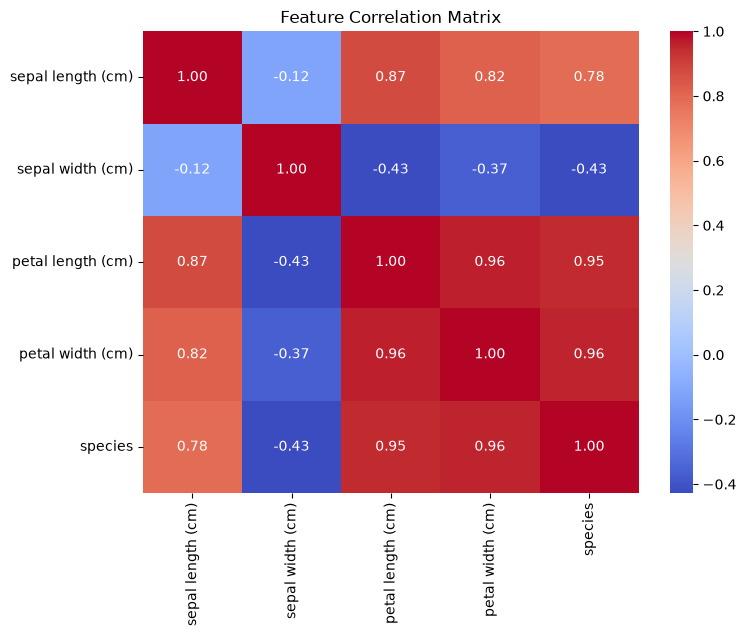

In [21]:
# Correlation between features

correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")
plt.show()

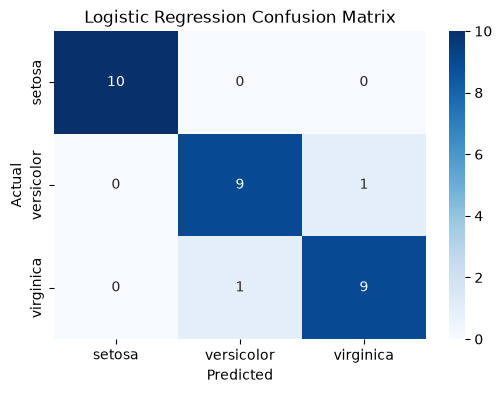

In [22]:
# Confusion Matrix - Logistic Regression

cm_logistic = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

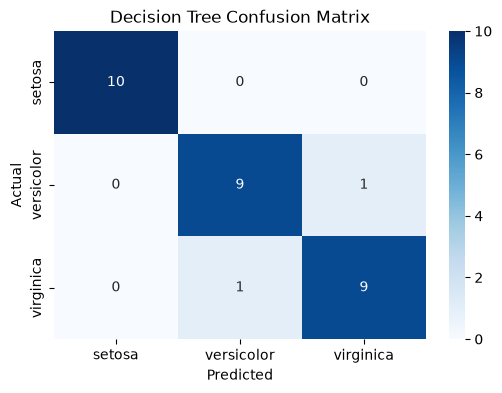

In [23]:
# Confusion Matrix - Decision Tree

cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.show()

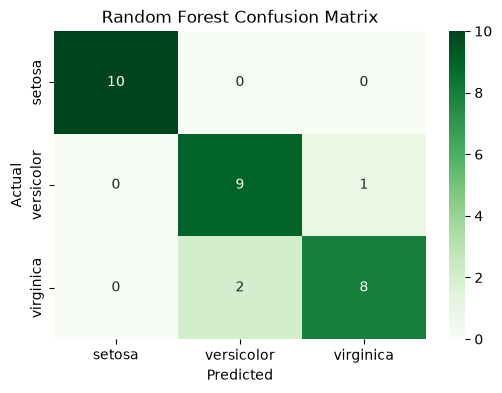

In [24]:
# Confusion Matrix - Random Forest

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

Feature Selection Discussion:
Based on the correlation analysis, petal length and petal width are the most discriminative features for classifying Iris species. Both features show a strong positive correlation with the target species, while sepal width has a weaker relationship. Therefore, petal length and petal width are particularly useful features for distinguishing between the three Iris species.


In [25]:
# Final Model Comparison

print("Model Performance Comparison")
print("-" * 35)

for model, accuracy in model_accuracies.items():
    print(f"{model}: {accuracy:.2%}")

Model Performance Comparison
-----------------------------------
Logistic Regression: 93.33%
KNN: 100.00%
Decision Tree: 93.33%
Random Forest: 90.00%


Best-Performing Model:
Among the four models evaluated, K-Nearest Neighbors (KNN) performed the best with an accuracy of 100% on the test dataset. Logistic Regression and Decision Tree achieved 93.33%, while Random Forest achieved 90%. KNN also produced perfect precision, recall, and F1-scores of 1.00 for all three Iris species. Therefore, KNN is selected as the best-performing model for this Iris flower classification task.

## Conclusion

In this project, the Iris flower dataset was analyzed and classification models were developed to predict the species of Iris flowers. Exploratory data analysis and visualization were performed to understand the dataset and identify important features. Petal length and petal width were found to be the most discriminative features for distinguishing between the Iris species.

Four classification algorithms — Logistic Regression, K-Nearest Neighbors (KNN), Decision Tree, and Random Forest — were trained and evaluated. Among these models, KNN achieved the highest accuracy of **100%** on the test dataset, with perfect precision, recall, and F1-score for all three Iris species. Therefore, KNN was selected as the best-performing model for this classification task.
